
=== BG - Lep  [GN2Tracks_KGC_20261119-T212322, epoch=049] ===
  N señal = 35,380   N fondo = 44,019   AUC = 0.8742
  eff_sig = 60% -> 1-eff_bg = 0.9097   rechazo =     11.1   (corte p_sig > 0.7217)
  eff_sig = 70% -> 1-eff_bg = 0.8591   rechazo =      7.1   (corte p_sig > 0.6262)
  eff_sig = 80% -> 1-eff_bg = 0.7819   rechazo =      4.6   (corte p_sig > 0.4994)
  eff_sig = 90% -> 1-eff_bg = 0.6420   rechazo =      2.8   (corte p_sig > 0.3257)
  loss (train_loss VS step_chart_data.json): mejor val_loss 0.4451 en epoch 48   (epoch usada para la ROC: 49)

=== BG - Had & Lep - NoBalanced  [GN2Tracks_KG_HadLep_20261125-T112854, epoch=049] ===
  N señal = 56,034   N fondo = 59,687   AUC = 0.8661
  eff_sig = 60% -> 1-eff_bg = 0.9015   rechazo =     10.1   (corte p_sig > 0.7084)
  eff_sig = 70% -> 1-eff_bg = 0.8429   rechazo =      6.4   (corte p_sig > 0.6183)
  eff_sig = 80% -> 1-eff_bg = 0.7556   rechazo =      4.1   (corte p_sig > 0.5102)
  eff_sig = 90% -> 1-eff_bg = 0.6085   rechazo =   

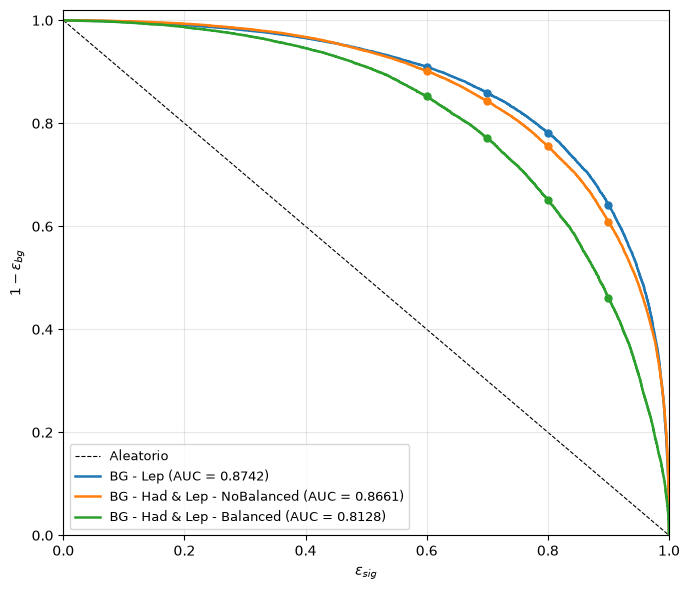

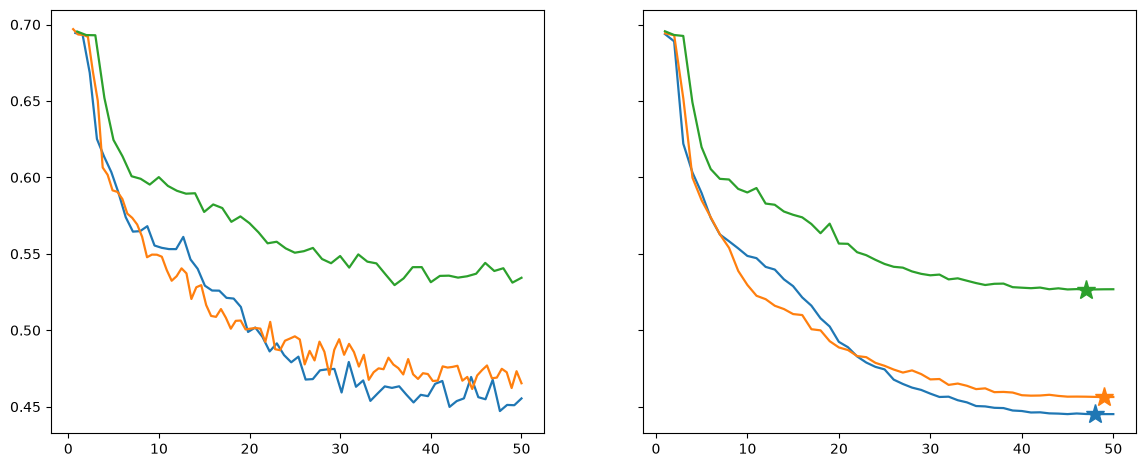


modelo                            AUC    1-eb@60%    1-eb@70%    1-eb@80%    1-eb@90%    val_min   ep_min
---------------------------------------------------------------------------------------------------------------
BG - Lep                       0.8742      0.9097      0.8591      0.7819      0.6420     0.4451       48
BG - Had & Lep - NoBalanced    0.8661      0.9015      0.8429      0.7556      0.6085     0.4563       49
BG - Had & Lep - Balanced      0.8128      0.8521      0.7712      0.6516      0.4610     0.5266       47

Guardado: /home/usuario/VSCode/diHiggs-Project/OutTrainings/Roc_comparison.png
          /home/usuario/VSCode/diHiggs-Project/OutTrainings/Loss_comparison.png


In [3]:
"""ROC y curvas de loss comparadas entre varios entrenamientos de `salt test`."""

import json
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- Ajustar ---
OUT_TRAINING_PATH = Path("/home/usuario/VSCode/diHiggs-Project/OutTrainings")

# (carpeta del entrenamiento, epoca, label de la curva)
GNNs = [
    ("GN2Tracks_KGC_20261119-T212322", "049", "BG - Lep"),
    ('GN2Tracks_KG_HadLep_20261125-T112854', "049", "BG - Had & Lep - NoBalanced"),
    ('GN2Tracks_KG_HadLep-Balanced_20261126-T181353', "049", "BG - Had & Lep - Balanced")
]

OBJ       = "jets"
SIG_CLASS = "hadtaujets"
WPS       = [0.6, 0.7, 0.8, 0.9]
ROC_AS    = OUT_TRAINING_PATH / "Roc_comparison.png"
LOSS_AS   = OUT_TRAINING_PATH / "Loss_comparison.png"

trapezoid = getattr(np, "trapezoid", None) or np.trapz  # numpy < 2.0

# un color por modelo, respetado en los tres paneles
COLORES  = plt.rcParams["axes.prop_cycle"].by_key()["color"]
color_de = {label: COLORES[i % len(COLORES)] for i, (_, _, label) in enumerate(GNNs)}


# ---------- scores y ROC ----------

def find_test_file(run_dir, epoch, sample):
    matches = sorted((run_dir / "ckpts").glob(f"epoch={epoch}-*__test_{sample}*.h5"))
    if not matches:
        raise FileNotFoundError(f"No hay test '{sample}' para epoch={epoch} en {run_dir / 'ckpts'}")
    return matches[0]


def load(fname):
    with h5py.File(fname, "r") as h:
        d = h[OBJ]
        score = next((n for n in d.dtype.names if n.endswith(f"_p{SIG_CLASS}")), None)
        if score is None:
            raise KeyError(f"No hay '*_p{SIG_CLASS}' en {fname.name}. Campos: {d.dtype.names}")
        return d.fields(score)[:].astype(np.float64)


def roc(s_sig, s_bkg):
    scores = np.concatenate([s_sig, s_bkg])
    is_sig = np.concatenate([np.ones_like(s_sig), np.zeros_like(s_bkg)])
    order  = np.argsort(-scores, kind="stable")
    e_sig  = np.concatenate([[0], np.cumsum(is_sig[order]) / len(s_sig)])
    e_bkg  = np.concatenate([[0], np.cumsum(1 - is_sig[order]) / len(s_bkg)])
    return e_sig, e_bkg, trapezoid(1 - e_bkg, e_sig)


# ---------- curvas de loss ----------

def _leer_plotly(path):
    with open(path) as f:
        fig = json.load(f)
    trazas = fig["data"] if isinstance(fig, dict) else fig
    t = max((d for d in trazas if d.get("x") and d.get("y")), key=lambda d: len(d["x"]))
    return np.asarray(t["x"], float), np.asarray(t["y"], float)


def load_loss(run_dir, epoch):
    """(ep_train, loss_train, ep_val, loss_val, fuente) o None si no hay datos."""
    # 1) metrics.csv del CSVLogger de Lightning
    for csv in sorted(run_dir.rglob("metrics.csv")):
        df   = pd.read_csv(csv)
        cols = {c.lower(): c for c in df.columns}
        c_tr = next((cols[c] for c in cols if "train" in c and "loss" in c), None)
        c_va = next((cols[c] for c in cols if "val"   in c and "loss" in c), None)
        c_ep = cols.get("epoch")
        if c_tr and c_va and c_ep:
            tr = df[[c_ep, c_tr]].dropna().groupby(c_ep).last().reset_index()
            va = df[[c_ep, c_va]].dropna().groupby(c_ep).last().reset_index()
            return (tr[c_ep].to_numpy(), tr[c_tr].to_numpy(),
                    va[c_ep].to_numpy(), va[c_va].to_numpy(), csv.name)

    # 2) exports json: cualquier archivo cuyo nombre contenga train_loss / val_loss
    def _buscar(patron):
        hits = sorted(p for p in run_dir.rglob("*.json") if patron in p.name.lower())
        return hits[0] if hits else None

    j_tr, j_va = _buscar("train_loss"), _buscar("val_loss")
    if j_tr and j_va:
        x_tr, y_tr = _leer_plotly(j_tr)
        x_va, y_va = _leer_plotly(j_va)
        n_ep = int(epoch) + 1          # el checkpoint 049 implica 50 epochs
        return (x_tr / (x_tr.max() / n_ep), y_tr,
                x_va / (x_va.max() / n_ep), y_va, j_tr.name)

    return None


# ---------- figuras ----------

fig_roc, ax_roc = plt.subplots(figsize=(7, 6))
ax_roc.plot([0, 1], [1, 0], "k--", lw=0.8, label="Aleatorio", zorder=1)

fig_loss, ax_loss = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

resumen = []

for carpeta, epoch, label in GNNs:
    run_dir = OUT_TRAINING_PATH / carpeta
    color   = color_de[label]

    # --- ROC ---
    s_sig = load(find_test_file(run_dir, epoch, "signal"))
    s_bkg = load(find_test_file(run_dir, epoch, "background"))
    e_sig, e_bkg, auc = roc(s_sig, s_bkg)
    ax_roc.plot(e_sig, 1 - e_bkg, lw=1.8, color=color, label=f"{label} (AUC = {auc:.4f})")

    print(f"\n=== {label}  [{carpeta}, epoch={epoch}] ===")
    print(f"  N señal = {len(s_sig):,}   N fondo = {len(s_bkg):,}   AUC = {auc:.4f}")

    fila = {"label": label, "auc": auc}
    for wp in WPS:
        cut = np.percentile(s_sig, np.clip(100 * (1 - wp), 0, 100))
        eb  = np.mean(s_bkg > cut)
        rechazo = np.inf if eb == 0 else 1.0 / eb
        print(f"  eff_sig = {wp:.0%} -> 1-eff_bg = {1 - eb:.4f}   "
              f"rechazo = {rechazo:>8.1f}   (corte p_sig > {cut:.4f})")
        ax_roc.plot(wp, 1 - eb, "o", color=color, ms=5, zorder=3)
        fila[wp] = 1 - eb

    # --- loss ---
    datos = load_loss(run_dir, epoch)
    if datos is None:
        print(f"  AVISO: no encontre metrics.csv ni train/val_loss.json en {run_dir}")
        fila["val_min"] = fila["ep_min"] = np.nan
    else:
        ep_tr, l_tr, ep_va, l_va, fuente = datos
        ax_loss[0].plot(ep_tr, l_tr, lw=1.6, color=color, label=label)
        ax_loss[1].plot(ep_va, l_va, lw=1.6, color=color, label=label)

        i = int(np.argmin(l_va))
        ax_loss[1].plot(ep_va[i], l_va[i], "*", color=color, ms=14, zorder=5)
        print(f"  loss ({fuente}): mejor val_loss {l_va[i]:.4f} en epoch {ep_va[i]:.0f}"
              f"   (epoch usada para la ROC: {int(epoch)})")
        fila["val_min"], fila["ep_min"] = l_va[i], ep_va[i]

    resumen.append(fila)

ax_roc.set_xlabel(r"$\epsilon_{sig}$")
ax_roc.set_ylabel(r"$1 - \epsilon_{bg}$")
ax_roc.set_xlim(0, 1)
ax_roc.set_ylim(0, 1.02)
ax_roc.grid(alpha=0.3)
ax_roc.legend(loc="lower left", fontsize=9)
fig_roc.tight_layout()
fig_roc.savefig(ROC_AS, dpi=300)
plt.show(fig_roc)

for ax, titulo in zip(ax_loss, ["Train loss", "Validation loss"]):
    ax.set_xlabel("Epoch")
    ax.set_title(titulo)
    ax.grid(alpha=0.3, which="both")
    ax.legend(fontsize=9)
ax_loss[0].set_ylabel("Loss")
fig_loss.tight_layout()
fig_loss.savefig(LOSS_AS, dpi=300)
plt.show(fig_loss)

# ---------- tabla ----------
w = max(len(f["label"]) for f in resumen)
ancho = w + 12 + 12 * len(WPS) + 24
print("\n" + "=" * ancho)
print(f"{'modelo':<{w}}  {'AUC':>8}" + "".join(f"  {f'1-eb@{wp:.0%}':>10}" for wp in WPS)
      + f"  {'val_min':>9}  {'ep_min':>7}")
print("-" * ancho)
for f in sorted(resumen, key=lambda r: -r["auc"]):
    print(f"{f['label']:<{w}}  {f['auc']:>8.4f}" + "".join(f"  {f[wp]:>10.4f}" for wp in WPS)
          + f"  {f['val_min']:>9.4f}  {f['ep_min']:>7.0f}")
print("=" * ancho)
print(f"\nGuardado: {ROC_AS}\n          {LOSS_AS}")